# This is a sample Jupyter Notebook

Below is an example of a code cell. 
Put your cursor into the cell and press Shift+Enter to execute it and select the next one, or click 'Run Cell' button.

Press Double Shift to search everywhere for classes, files, tool windows, actions, and settings.

To learn more about Jupyter Notebooks in PyCharm, see [help](https://www.jetbrains.com/help/pycharm/ipython-notebook-support.html).
For an overview of PyCharm, go to Help -> Learn IDE features or refer to [our documentation](https://www.jetbrains.com/help/pycharm/getting-started.html).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
import scipy.linalg
from matplotlib.lines import Line2D

plt.rcParams['figure.figsize'] = [12, 6]
plt.rcParams['figure.dpi'] = 100

Model generat: 51 noduri.
Sistemul rezultat: 102 ecuatii x 102 necunoscute.


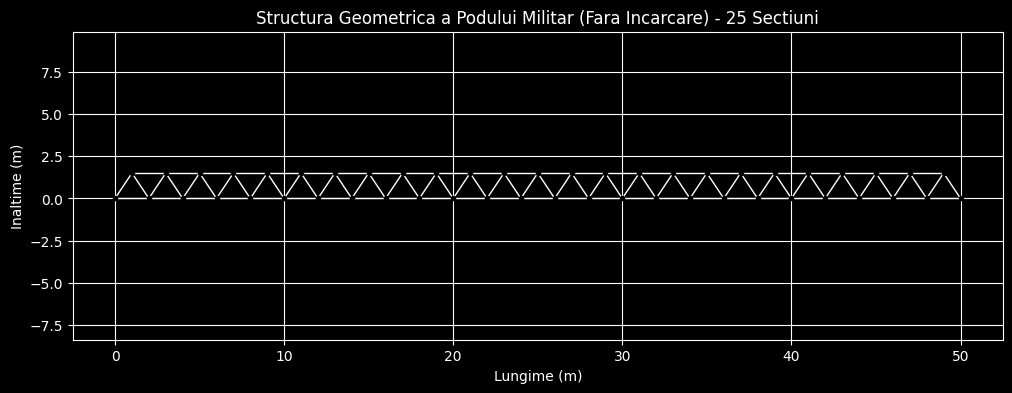

In [4]:
def generate_bridge_system(num_sections):
    """
    Genereaza sistemul Ax=b pentru un pod de tip 'Warren Truss'.
    num_sections: Numarul de segmente triunghiulare.
    Return: A (matricea), b (vectorul incarcari), nodes (coordonate), members (conexiuni)
    """
    # setari parametrii
    L = 2.0  # Lungimea unui segment (metri)
    H = 1.5  # Inaltimea (metri)
    Load = 10000.0 # Greutatea unui vehicul aplicata pe nodurile centrale (Newtoni)

    #Generare coordonate
    nodes = []
    # Alternam noduri jos (y=0) si sus (y=H)
    for i in range(num_sections + 1):
        nodes.append((i * L, 0))       # Nod Jos
        if i < num_sections:
            nodes.append((i * L + L/2, H)) # Nod Sus
    #   .           .           .
    #.      apoi .      apoi .      ....

    num_nodes = len(nodes)

    # --- 2. Definire Bare (Conexiuni intre noduri) ---
    members = []
    # Bare orizontale jos
    for i in range(0, num_nodes - 2, 2):
        members.append((i, i+2))
    # Bare orizontale sus
    for i in range(1, num_nodes - 2, 2):
        members.append((i, i+2))
    # Bare diagonale
    for i in range(num_sections):
        lower_left = 2*i
        upper = 2*i + 1
        lower_right = 2*i + 2
        members.append((lower_left, upper)) #bara /
        members.append((upper, lower_right)) #bara \

    num_members = len(members)

    # --- 3. Construire Matrice A si Vector b ---
    # Avem 2 ecuatii per nod (echilibru X si Y).
    # Necunoscute: Fortele din bare (num_members) + 3 Reactiuni (Rx_stanga, Ry_stanga, Ry_dreapta)
    num_eq = 2 * num_nodes
    num_vars = num_members + 3

    A = np.zeros((num_eq, num_vars))
    b = np.zeros(num_eq)

    # Completare Matrice A cu cosinusuri directori
    for k, (node_i, node_j) in enumerate(members):
        xi, yi = nodes[node_i]
        xj, yj = nodes[node_j]
        dist = np.sqrt((xj-xi)**2 + (yj-yi)**2)

        # Cosinus (dx) si Sinus (dy)
        c = (xj - xi) / dist
        s = (yj - yi) / dist

        # Ecuatiile pentru Nodul i
        A[2*node_i, k] += c
        A[2*node_i+1, k] += s

        # Ecuatiile pentru Nodul j (sens opus)
        A[2*node_j, k] -= c
        A[2*node_j+1, k] -= s

    # Adaugare Reactiuni (Suporti)
    # Nod 0 (Stanga Jos): Fixat X si Y
    A[0, num_members] = 1     # Reactiune H
    A[1, num_members+1] = 1   # Reactiune V
    # Ultimul nod de jos: Fixat doar Y (rola)
    last_node_idx = 2 * num_sections
    A[2*last_node_idx+1, num_members+2] = 1

    # --- 4. Aplicare Incarcari (Greutate Tanc) ---
    # Aplicam forta pe cateva noduri centrale de jos
    mid_start = num_sections // 2 - 2
    mid_end = num_sections // 2 + 2
    for i in range(mid_start, mid_end):
        if i >= 0 and i*2 < num_nodes:
             b[2*(i*2) + 1] -= Load # Forta in jos pe axa Y

    return A, b, nodes, members

# --- VIZUALIZARE INITIALA (STRUCTURA) ---
# Generam un pod cu 25 sectiuni (aprox 100+ ecuatii)
NUM_SECTIUNI = 25
A, b, nodes, members = generate_bridge_system(NUM_SECTIUNI)

print(f"Model generat: {len(nodes)} noduri.")
print(f"Sistemul rezultat: {A.shape[0]} ecuatii x {A.shape[1]} necunoscute.")

# Plotare "Schelet" Pod
plt.figure(figsize=(12, 4))
for (i, j) in members:
    p1, p2 = nodes[i], nodes[j]
    plt.plot([p1[0], p2[0]], [p1[1], p2[1]], 'w-', lw=1) # Linii albe simple, schimba culoarea daca face fite IDE-ul

plt.plot([n[0] for n in nodes], [n[1] for n in nodes], 'ko', markersize=3)
plt.title(f"Structura Geometrica a Podului Militar (Fara Incarcare) - {NUM_SECTIUNI} Sectiuni")
plt.xlabel("Lungime (m)")
plt.ylabel("Inaltime (m)")
plt.axis('equal')
plt.grid(True)
plt.show()

In [3]:
def UTRIS(U, b):
    """
    Algoritm de Substitutie Inapoi (pentru sisteme superior triunghiulare).
    Rezolva Ux = b.
    """
    n = len(b)
    x = np.zeros(n)
    for i in range(n - 1, -1, -1):
        # x[i] = (b[i] - suma(U[i,j]*x[j])) / U[i,i]
        s = sum(U[i][j] * x[j] for j in range(i + 1, n))
        if U[i][i] == 0:
             # Tratare caz pivot zero (teoretic nu ajungem aici cu GPP pe sisteme nesingulare)
            continue
        x[i] = (b[i] - s) / U[i][i]
    return x

def gauss_partial_pivoting(A_in, b_in):
    """
    Eliminare Gaussiana cu Pivotare Partiala (GPP).
    Transforma sistemul Ax=b in Ux=y si apoi rezolva cu UTRIS.
    """
    # Copiem ca sa nu stricam matricile originale
    A = A_in.copy()
    b = b_in.copy()
    n = len(b)
    # Daca matricea nu e patratica (mai multe ecuatii decat necunoscute),
    # ne limitam la n_vars (pentru acest proiect A e aprox patratica)
    n_vars = A.shape[1]

    limit = min(n, n_vars)

    # 1. Etapa de Eliminare (Triangularizare)
    for k in range(limit):
        # A. Pivotare: Gasim maximul pe coloana k sub diagonala
        pivot_index = k + np.argmax(np.abs(A[k:, k]))

        if abs(A[pivot_index, k]) < 1e-12:
            # Daca pivotul e aproape 0, trecem mai departe (sau semnalam eroare)
            continue

        # Interschimbam liniile k si pivot_index
        if pivot_index != k:
            A[[k, pivot_index]] = A[[pivot_index, k]]
            b[[k, pivot_index]] = b[[pivot_index, k]]

        # B. Eliminare
        for i in range(k + 1, n):
            factor = A[i, k] / A[k, k]
            A[i, k:] -= factor * A[k, k:]
            b[i] -= factor * b[k]

    # 2. Etapa de Substitutie
    # Decupam sistemul la dimensiunea patratica relevanta
    return UTRIS(A[:n_vars, :n_vars], b[:n_vars])

In [82]:
print("--- Start Analiza Numerica ---")

# 1. Solutia Noastra (Gauss GPP)
start_t = time.time()
x_custom = gauss_partial_pivoting(A, b)
end_t = time.time()
time_custom = end_t - start_t
print(f"Solutie Custom (Gauss):  {time_custom:.5f} secunde")

# 2. Solutia Standard Python (NumPy)
# Deoarece matricea noastra poate fi usor dreptunghiulara (2N ecuatii, M vars),
# folosim 'lstsq' (Least Squares) care e cea mai robusta metoda din NumPy
start_t = time.time()
x_numpy, _, _, _ = np.linalg.lstsq(A, b, rcond=None)
end_t = time.time()
time_numpy = end_t - start_t
print(f"Solutie Python (NumPy):  {time_numpy:.5f} secunde")

# 3. Verificarea Erorilor
# Calculam diferenta intre solutia noastra si cea "perfecta" (NumPy)
diff_norm = np.linalg.norm(x_custom - x_numpy)
print(f"Diferenta intre solutii (Eroare): {diff_norm:.2e}")

# Verificam cat de bine satisface ecuatia Ax=b
residual = np.linalg.norm(np.dot(A, x_custom) - b)
print(f"Reziduul sistemului (||Ax - b||): {residual:.2e}")

--- Start Analiza Numerica ---
Solutie Custom (Gauss):  0.01900 secunde
Solutie Python (NumPy):  0.07602 secunde
Diferenta intre solutii (Eroare): 2.38e-08
Reziduul sistemului (||Ax - b||): 8.18e-11



Se ruleaza testul de performanta (asteptati)...


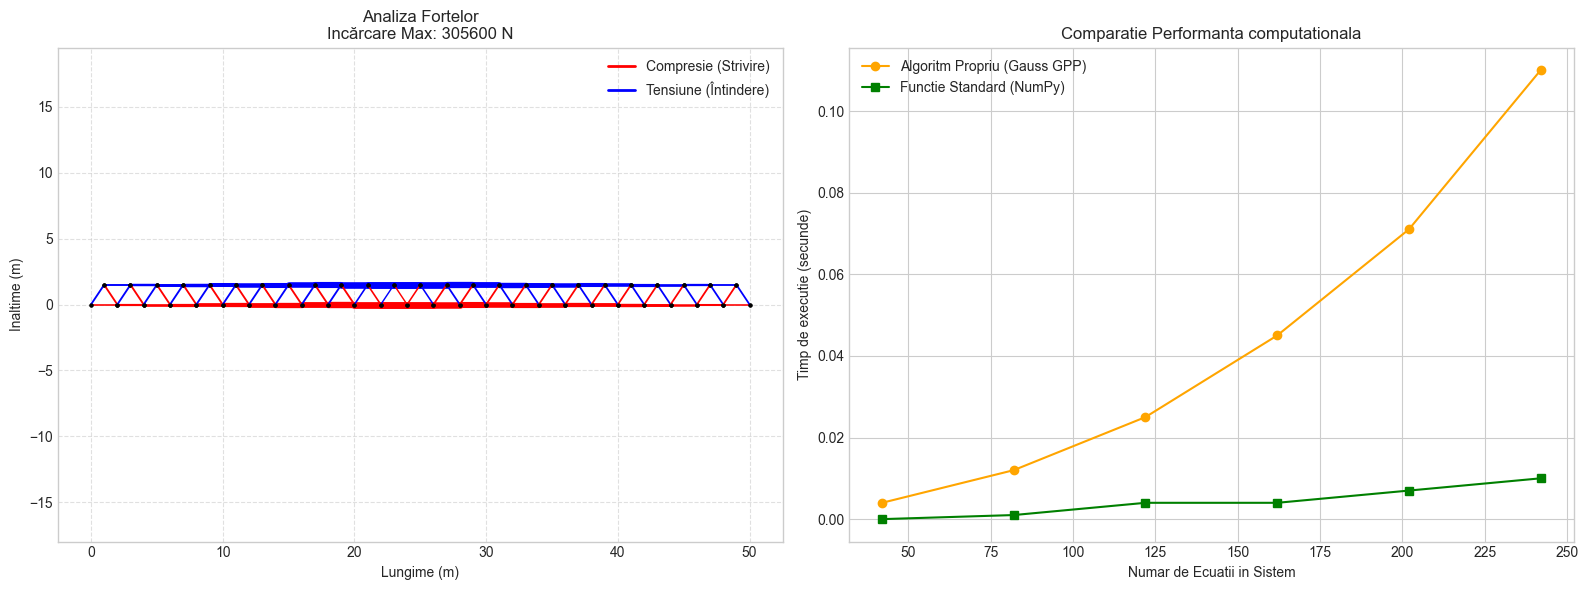

Analiza completa.


In [86]:
from matplotlib.lines import Line2D # Necesara pentru legenda custom

plt.figure(figsize=(16, 6))

# --- GRAFIC 1: Harta de Tensiune in Pod ---
plt.subplot(1, 2, 1)

# Extragem fortele
forces = x_custom[:len(members)]
max_force = np.max(np.abs(forces))

# Desenam barele podului
for k, (i, j) in enumerate(members):
    xi, yi = nodes[i]
    xj, yj = nodes[j]
    f = forces[k]

    # Logica culorilor
    if f < 0:
        color = 'red'     # Compresie
    else:
        color = 'blue'    # Tensiune

    # Grosimea liniei proportionala cu forta
    width = 1 + 4 * (abs(f) / max_force)

    plt.plot([xi, xj], [yi, yj], color=color, linewidth=width)

    # Desenam nodurile
    plt.plot(xi, yi, 'ko', markersize=2)
    plt.plot(xj, yj, 'ko', markersize=2)

# --- ADAUGARE LEGENDA ---
# Definim manual elementele legendei pentru a evita duplicarea
legend_elements = [
    Line2D([0], [0], color='red', lw=2, label='Compresie (Strivire)'),
    Line2D([0], [0], color='blue', lw=2, label='Tensiune (Întindere)')
]
plt.legend(handles=legend_elements, loc='upper right')

plt.title(f"Analiza Fortelor\nIncărcare Max: {max_force:.0f} N")
plt.xlabel("Lungime (m)")
plt.ylabel("Inaltime (m)")
plt.axis('equal')
plt.grid(True, linestyle='--', alpha=0.6)


# --- GRAFIC 2: Analiza de Performanta ---
plt.subplot(1, 2, 2)

sizes = [10, 20, 30, 40, 50, 60]
times_custom = []
times_np = []
eq_counts = []

print("\nSe ruleaza testul de performanta (asteptati)...")
for s in sizes:
    A_temp, b_temp, _, _ = generate_bridge_system(s)
    eq_counts.append(A_temp.shape[0])

    # Custom
    t0 = time.time()
    gauss_partial_pivoting(A_temp, b_temp)
    times_custom.append(time.time() - t0)

    # NumPy
    t0 = time.time()
    np.linalg.lstsq(A_temp, b_temp, rcond=None)
    times_np.append(time.time() - t0)

plt.plot(eq_counts, times_custom, 'o-', label='Algoritm Propriu (Gauss GPP)', color='orange')
plt.plot(eq_counts, times_np, 's-', label='Functie Standard (NumPy)', color='green')
plt.title("Comparatie Performanta computationala")
plt.xlabel("Numar de Ecuatii in Sistem")
plt.ylabel("Timp de executie (secunde)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
print("Analiza completa.")